# Opponent-aware Double DQN in Chef’s Hat

Task 2, 7043SCN. Student: Sampath Adimalla, ID 17522555, opponent-modelling variant. This review notebook loads the saved experiment CSVs and checkpoints, then recomputes the analysis figures and tables.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
ROOT = Path.cwd()
if not (ROOT / 'configs/standard.yaml').exists():
    ROOT = ROOT.parent
from sampath_rl.core import ACTIONS, SingleAgentEnv, UPSTREAM_SOURCE
from sampath_rl.agents import DQNAgent, QNetwork
from sampath_rl.experiment import make_opponents
from sampath_rl.policy import progress_mask
print('Assigned variant:', 17522555 % 7)
print('Official actions:', len(ACTIONS))
print('Engine source:', UPSTREAM_SOURCE)
print('Network parameters:', sum(p.numel() for p in QNetwork().parameters()))
print(json.loads((ROOT/'docs/hardware_software.json').read_text()))

Assigned variant: 1
Official actions: 200
Engine source: /home/ubuntu/work/ChefsHatGYM/src
Network parameters: 50632
{'python': '3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]', 'platform': 'Linux-6.18.38+-aarch64-with-glibc2.39', 'logical_cpus': 6, 'memory_bytes': 25599549440, 'gpu': None, 'torch': '2.14.1+cpu', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'pytest': '9.1.1', 'pyyaml': '6.0.3', 'upstream_commit': 'bf882e55eccd537d189f8b99fef1ad104339c92b'}


## Observation and action handling

The 64-input vector contains the acting player’s own hand histogram and public state. The aware variant enables 15 public-behaviour statistics; other DQN variants zero them. The original official legality is separate from the shared empty-board progress constraint. See `docs/PASS_LOOP_DIAGNOSIS.md`.

In [2]:
env = SingleAgentEnv(make_opponents('mixed', 777888), seat=0, aware=True)
state, official_mask = env.reset(seed=777888)
policy_mask = progress_mask(state, official_mask)
print('State shape:', state.shape, 'official mask shape:', official_mask.shape)
print('Official choices:', [ACTIONS[i] for i in np.flatnonzero(official_mask)])
print('Policy choices:', [ACTIONS[i] for i in np.flatnonzero(policy_mask)])
print('Public opponent features:', state[47:62])

State shape: (64,) official mask shape: (200,)
Official choices: ['C11;Q1;J0', 'C11;Q2;J0', 'C11;Q3;J0', 'C11;Q4;J0']
Policy choices: ['C11;Q1;J0', 'C11;Q2;J0', 'C11;Q3;J0', 'C11;Q4;J0']
Public opponent features: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Training protocol

Three DQN variants were trained for 600 matches at each of three independent seeds. Baselines are not trained. Final checkpoints, not held-out-selected checkpoints, are evaluated. The exact configuration and measured completed budgets follow.

In [3]:
import yaml
print(yaml.safe_load((ROOT/'configs/standard.yaml').read_text()))
metadata = [json.loads(p.read_text()) for p in sorted((ROOT/'results/training').glob('*_metadata.json'))]
display(pd.DataFrame([{k:m.get(k) for k in ['condition','training_seed','completed_episodes','steps','duration_seconds','status']} for m in metadata]))

{'environment_commit': 'bf882e55eccd537d189f8b99fef1ad104339c92b', 'environment_patch_sha256': '5b038a7114080abd7efbf2816cdce322dad8d1bddbaa20945f49f3e3ae1771bb', 'preset': 'standard', 'train_episodes': 600, 'training_seeds': [17, 29, 43], 'evaluation_seed_start': 9000000, 'evaluation_seeds': 32, 'seats': [0, 1, 2, 3], 'max_actions': 5000, 'shaping': 0.01, 'epsilon_start': 1.0, 'epsilon_end': 0.05, 'epsilon_decay_fraction': 0.8, 'network': {'learning_rate': 0.001, 'batch_size': 64, 'gamma': 0.99, 'learn_start': 256, 'update_every': 4, 'target_interval': 250, 'grad_clip': 10.0, 'capacity': 20000}}


,condition,training_seed,completed_episodes,steps,duration_seconds,status
0,dqn_aware,17,600,12427,58.318755,completed
1,dqn_aware,29,600,12291,58.122056,completed
2,dqn_aware,43,600,12287,57.650653,completed
3,dqn_mixed,17,600,12381,58.918244,completed
4,dqn_mixed,29,600,12362,58.878656,completed
5,dqn_mixed,43,600,12405,58.842809,completed
6,dqn_random,17,600,13271,65.556289,completed
7,dqn_random,29,600,13307,65.536809,completed
8,dqn_random,43,600,13477,66.177180,completed


## Held-out results

These tables are generated from match-level CSVs. Score is the official 3–0 finishing-point metric. The speed-normalised compatibility statistic is derived from older documentation, not an emitted V3 engine field. Paired uncertainty clusters by deal seed, retaining all seats and checkpoints.

In [4]:
overall = pd.read_csv(ROOT/'results/summaries/summary_overall.csv')
by_opponent = pd.read_csv(ROOT/'results/summaries/summary_by_opponent.csv')
paired = pd.read_csv(ROOT/'results/summaries/paired_differences.csv')
display(overall)
display(by_opponent)
display(paired)

,agent,opponent,aggregation,n_matches,wins,n_environment_seeds,n_training_seeds,n_deal_seed_blocks,ci95_method_primary,bootstrap_replicates,...,pass_frequency_ci95_bootstrap_high,mean_rounds,mean_rounds_ci95_bootstrap_low,mean_rounds_ci95_bootstrap_high,mean_duration_seconds,mean_duration_seconds_ci95_bootstrap_low,mean_duration_seconds_ci95_bootstrap_high,mean_performance_score,mean_performance_score_ci95_bootstrap_low,mean_performance_score_ci95_bootstrap_high
0,dqn_aware,all,macro_equal_opponents,1920,674,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.508337,16.327083,16.119766,16.545872,0.022678,0.022442,0.022926,1.055449,1.012011,1.098792
1,dqn_aware,all,pooled,1920,674,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.509563,16.327083,16.122891,16.538034,0.022678,0.022440,0.022927,1.055449,1.012667,1.098454
2,dqn_aware_features_off,all,macro_equal_opponents,1920,465,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.527195,16.546354,16.366133,16.731810,0.022678,0.022455,0.022903,0.880926,0.840150,0.922135
3,dqn_aware_features_off,all,pooled,1920,465,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.526978,16.546354,16.359883,16.729180,0.022678,0.022456,0.022907,0.880926,0.840174,0.919255
4,dqn_mixed,all,macro_equal_opponents,1920,709,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.516321,16.370313,16.155208,16.588542,0.021919,0.021646,0.022201,1.095266,1.044160,1.143642
5,dqn_mixed,all,pooled,1920,709,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.518019,16.370313,16.149440,16.582826,0.021919,0.021629,0.022200,1.095266,1.045881,1.144616
6,dqn_random,all,macro_equal_opponents,1920,649,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.520517,16.114062,15.898958,16.321367,0.021823,0.021511,0.022125,1.051994,1.002271,1.104601
7,dqn_random,all,pooled,1920,649,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.521579,16.114062,15.907292,16.326055,0.021823,0.021524,0.022129,1.051994,1.000179,1.102072
8,heuristic,all,macro_equal_opponents,640,378,32,1,32,bootstrap_environment_seed_block_percentile,3000,...,0.473803,15.532813,15.289023,15.775078,0.013094,0.012950,0.013238,1.509371,1.464274,1.554974
9,heuristic,all,pooled,640,378,32,1,32,bootstrap_environment_seed_block_percentile,3000,...,0.480013,15.532813,15.300000,15.778125,0.013094,0.012952,0.013250,1.509371,1.462128,1.554559


,agent,opponent,aggregation,n_matches,wins,n_environment_seeds,n_training_seeds,n_deal_seed_blocks,ci95_method_primary,bootstrap_replicates,...,pass_frequency_ci95_bootstrap_high,mean_rounds,mean_rounds_ci95_bootstrap_low,mean_rounds_ci95_bootstrap_high,mean_duration_seconds,mean_duration_seconds_ci95_bootstrap_low,mean_duration_seconds_ci95_bootstrap_high,mean_performance_score,mean_performance_score_ci95_bootstrap_low,mean_performance_score_ci95_bootstrap_high
0,dqn_aware,aggressive,per_opponent,384,41,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.570635,15.091146,14.744792,15.461003,0.020212,0.019875,0.020538,0.567607,0.494812,0.639727
1,dqn_aware,conservative,per_opponent,384,226,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.426877,15.106771,14.736914,15.539062,0.023938,0.023691,0.024190,1.613235,1.531629,1.692133
2,dqn_aware,mixed,per_opponent,384,100,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.502374,16.591146,16.289062,16.916667,0.022729,0.022454,0.023012,1.136542,1.063887,1.208198
3,dqn_aware,random,per_opponent,384,241,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.523094,20.328125,19.942708,20.737044,0.026227,0.025781,0.026713,1.222021,1.173153,1.265770
4,dqn_aware,switching,per_opponent,384,66,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.540336,14.518229,14.281250,14.778711,0.020285,0.019978,0.020598,0.737840,0.658751,0.820208
5,dqn_aware_features_off,aggressive,per_opponent,384,25,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.588237,14.755208,14.479167,15.020833,0.019304,0.019043,0.019573,0.409199,0.343404,0.470232
6,dqn_aware_features_off,conservative,per_opponent,384,164,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.446531,15.414062,15.062370,15.770898,0.024340,0.024130,0.024548,1.420158,1.352154,1.487852
7,dqn_aware_features_off,mixed,per_opponent,384,61,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.523342,17.247396,16.901042,17.583333,0.023537,0.023204,0.023861,0.946595,0.875401,1.016171
8,dqn_aware_features_off,random,per_opponent,384,175,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.545012,20.752604,20.330729,21.166667,0.026277,0.025842,0.026708,1.051056,0.990244,1.109628
9,dqn_aware_features_off,switching,per_opponent,384,40,32,3,32,bootstrap_environment_seed_block_percentile,3000,...,0.551520,14.562500,14.304688,14.820312,0.019930,0.019617,0.020253,0.577619,0.519463,0.634924


,comparison,candidate,reference,opponent,aggregation,n_matches,n_deal_seed_blocks,candidate_win_rate,reference_win_rate,win_rate_difference,win_rate_difference_ci95_bootstrap_low,win_rate_difference_ci95_bootstrap_high,ci95_method_primary,bootstrap_replicates
0,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,all,macro_equal_opponents,1920,32,0.351042,0.242188,0.108854,0.082812,0.132812,paired_bootstrap_shared_environment_seed_block...,3000
1,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,aggressive,per_opponent,384,32,0.106771,0.065104,0.041667,0.010417,0.075586,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
2,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,conservative,per_opponent,384,32,0.588542,0.427083,0.161458,0.096354,0.223958,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
3,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,mixed,per_opponent,384,32,0.260417,0.158854,0.101562,0.057227,0.145833,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
4,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,random,per_opponent,384,32,0.627604,0.455729,0.171875,0.117188,0.231771,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
5,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,switching,per_opponent,384,32,0.171875,0.104167,0.067708,0.031250,0.104167,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
6,dqn_aware - dqn_aware_features_off,dqn_aware,dqn_aware_features_off,all,pooled,1920,32,0.351042,0.242188,0.108854,0.082292,0.133854,paired_bootstrap_shared_environment_seed_block...,3000
7,dqn_aware - dqn_mixed,dqn_aware,dqn_mixed,all,macro_equal_opponents,1920,32,0.351042,0.369271,-0.018229,-0.047409,0.010937,paired_bootstrap_shared_environment_seed_block...,3000
8,dqn_aware - dqn_mixed,dqn_aware,dqn_mixed,aggressive,per_opponent,384,32,0.106771,0.135417,-0.028646,-0.070312,0.013021,paired_bootstrap_shared_deal_seed_blocks_perce...,3000
9,dqn_aware - dqn_mixed,dqn_aware,dqn_mixed,conservative,per_opponent,384,32,0.588542,0.617188,-0.028646,-0.083333,0.023438,paired_bootstrap_shared_deal_seed_blocks_perce...,3000


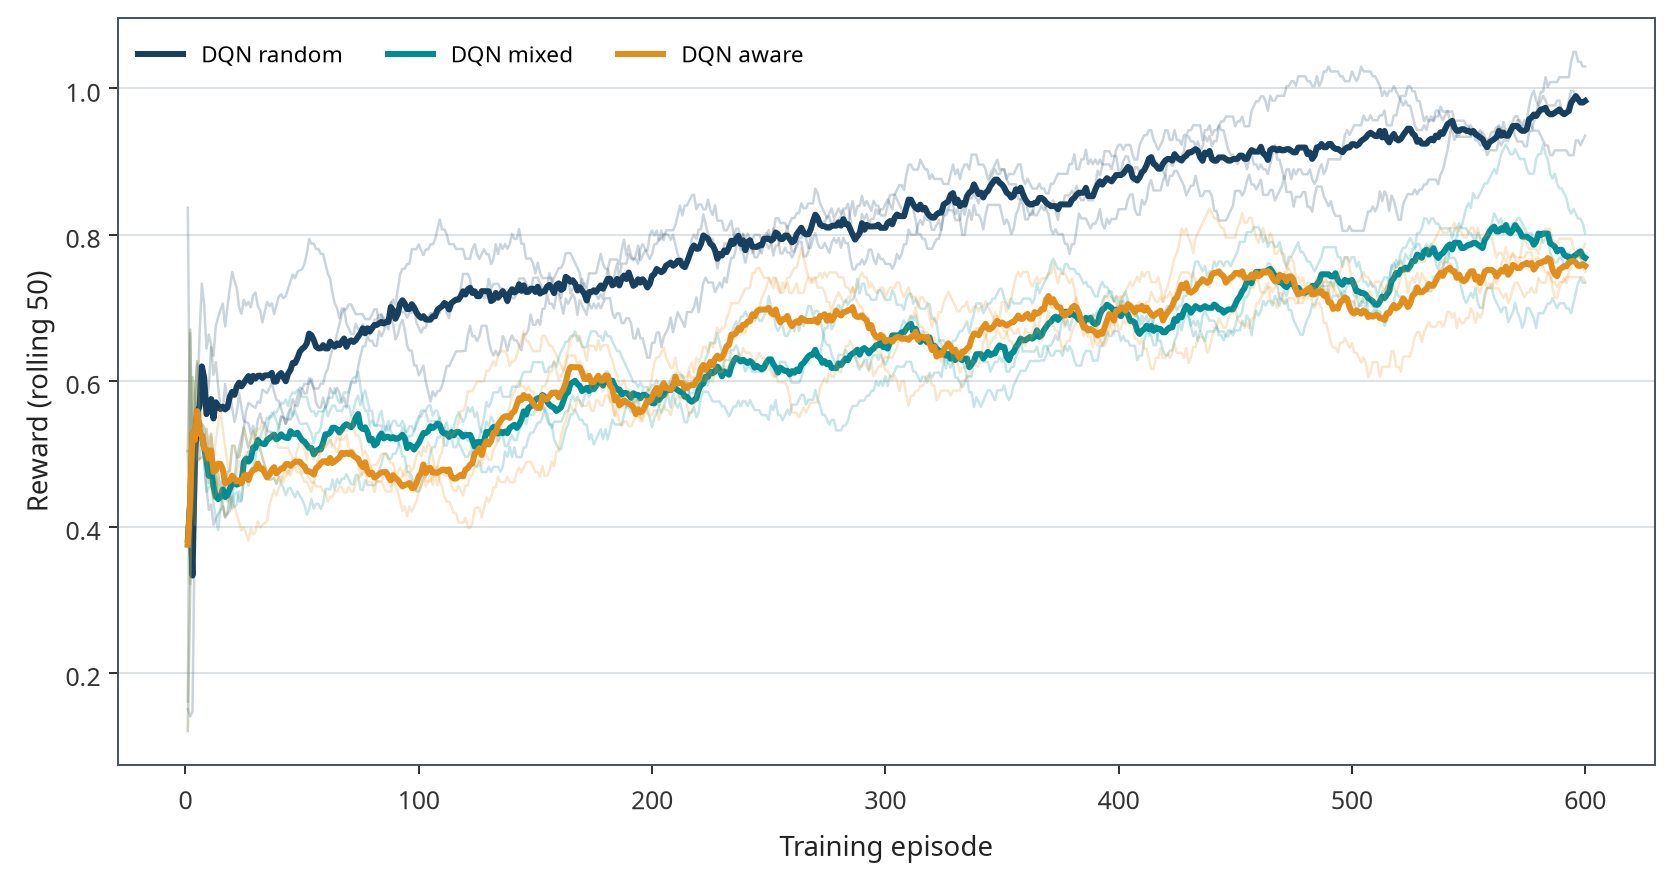

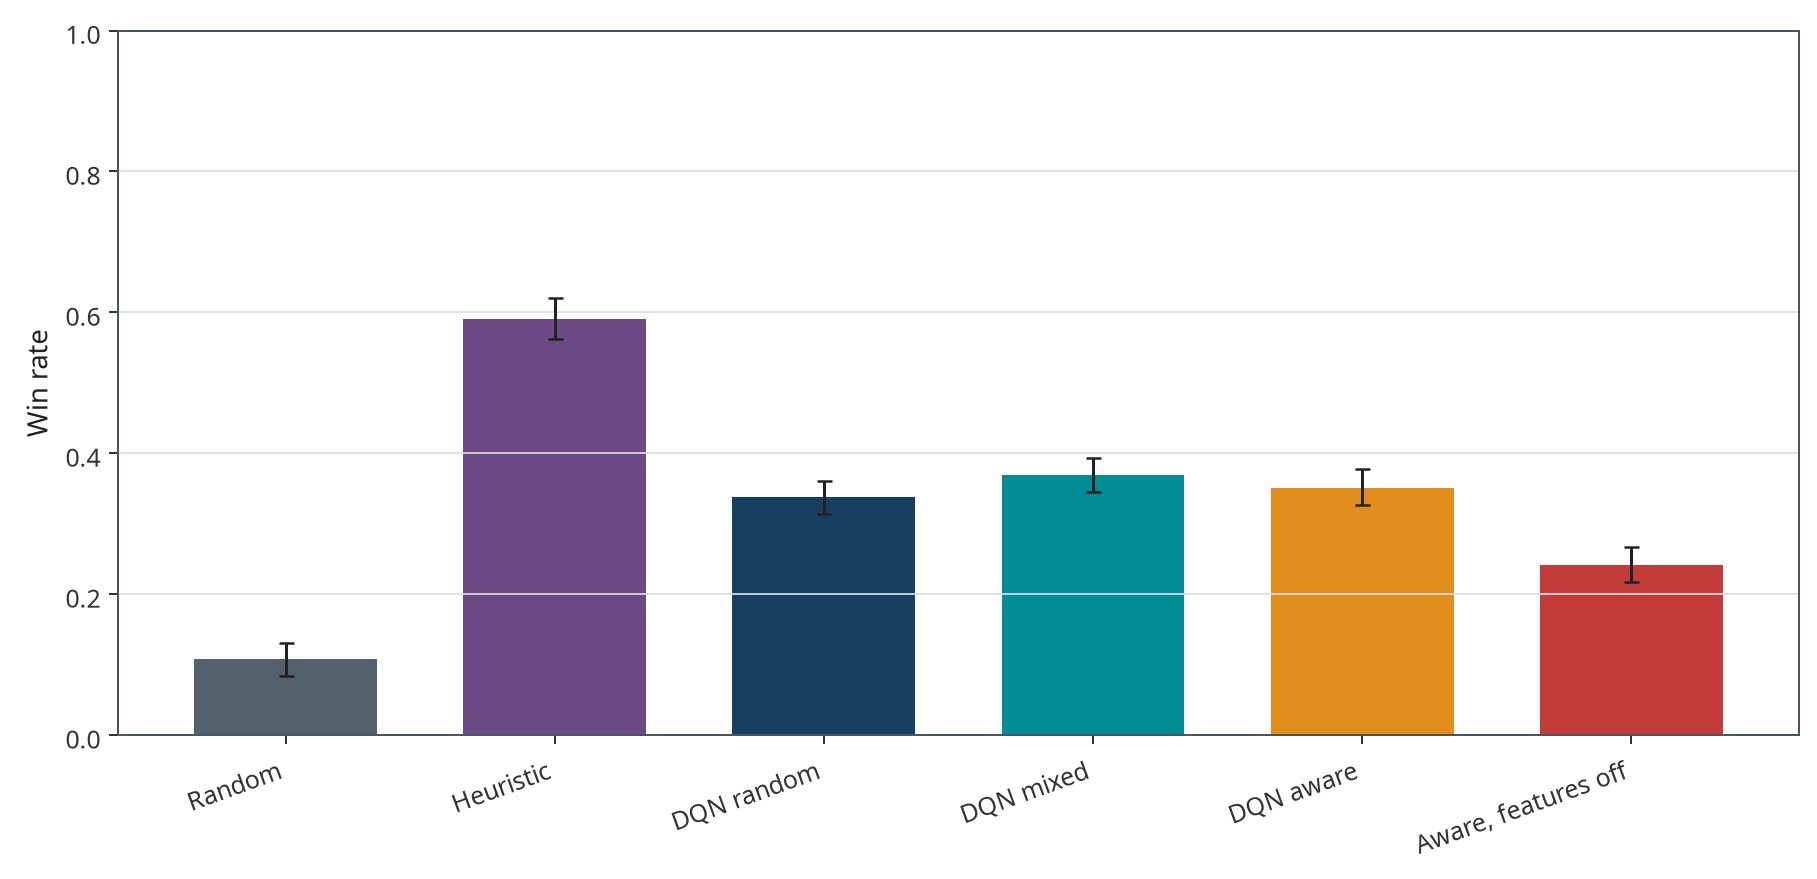

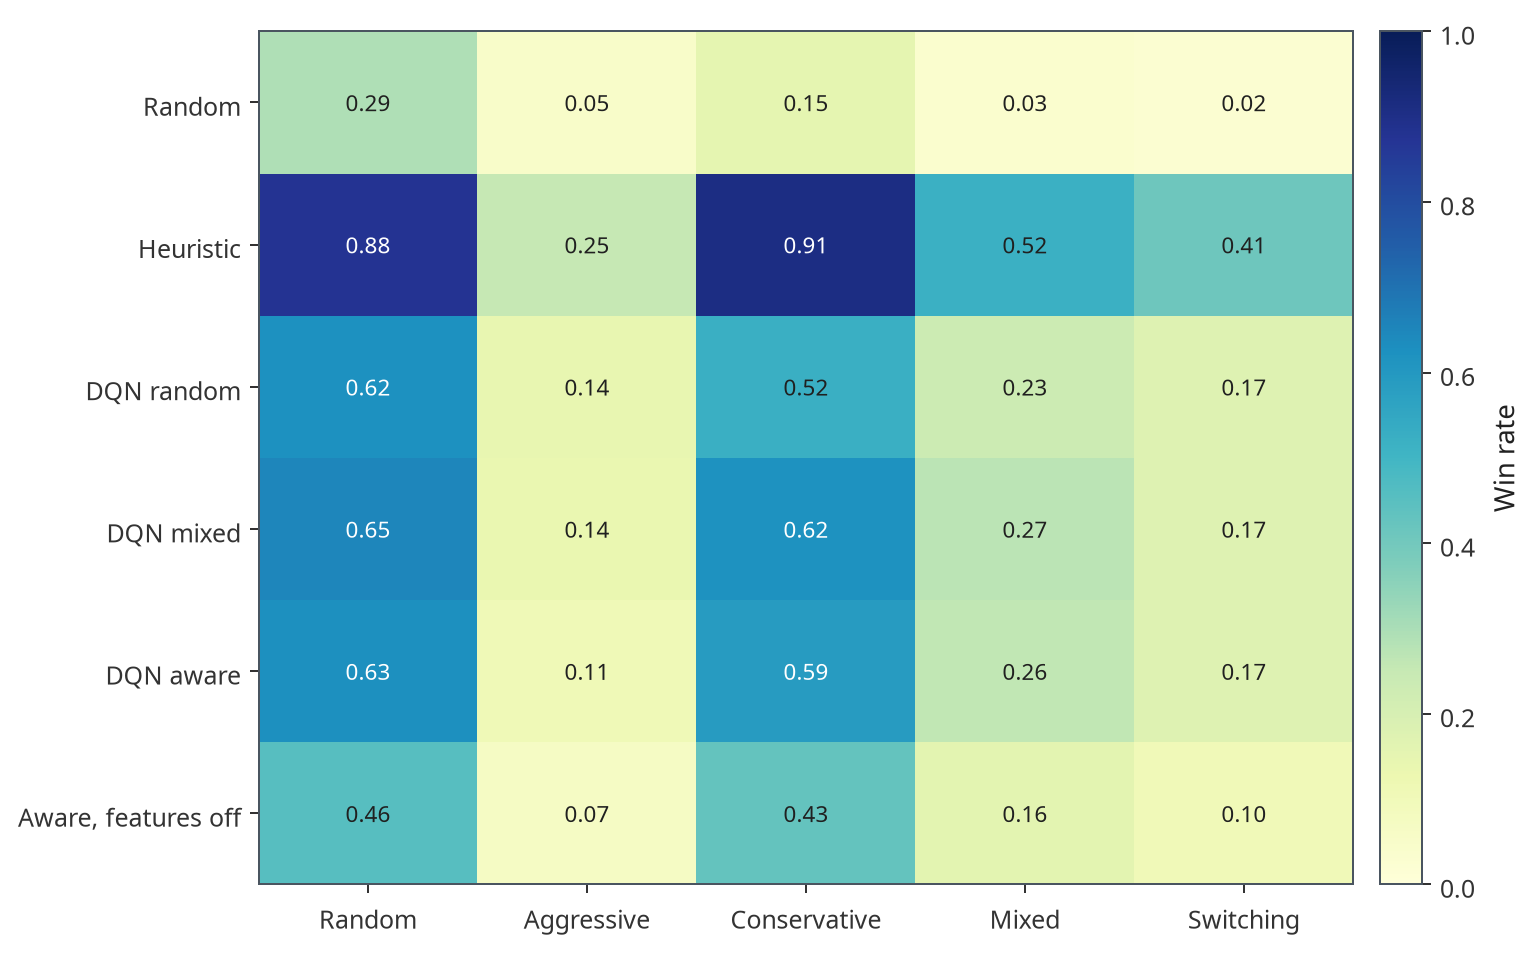

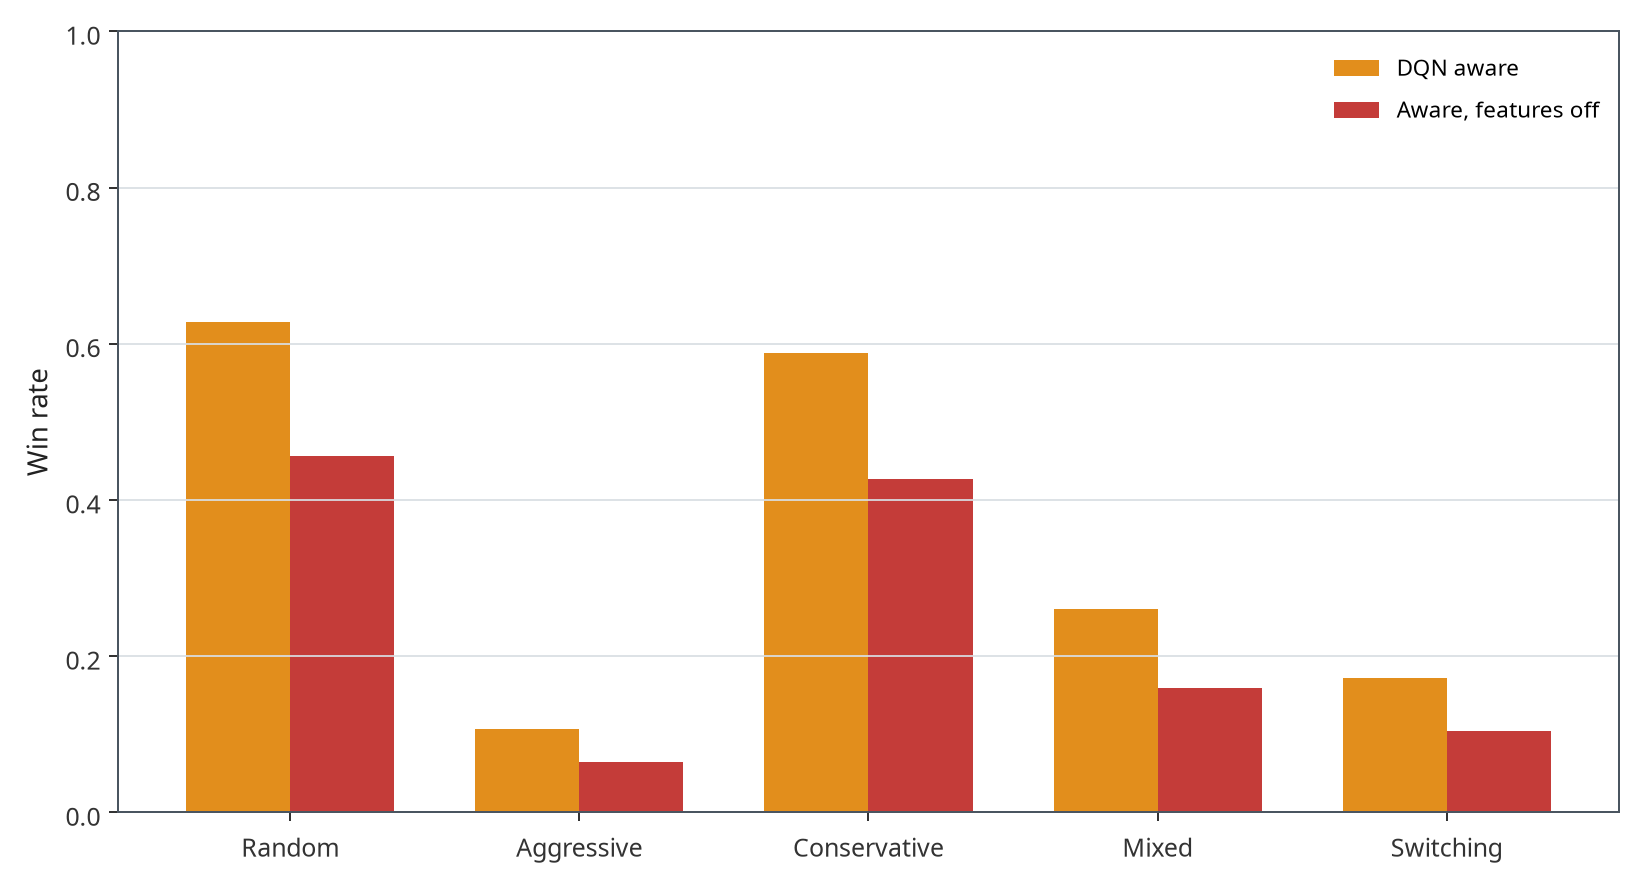

In [5]:
from IPython.display import Image, display
for name in ['learning_curves','win_rates','opponent_heatmap','ablation']:
    display(Image(filename=str(ROOT/'results/figures'/f'{name}.png')))

## Complete official match with a trained checkpoint

The following executes one natural complete game, without exploration or learning. It is a gameplay test, not a synthetic student viva recording. The fixed demonstration seed is not chosen for a favourable outcome.

In [6]:
agent = DQNAgent.load(ROOT/'checkpoints/dqn_aware_seed17.pt')
env = SingleAgentEnv(make_opponents('mixed',777888),seat=0,aware=True,shaping=0.0)
state, mask = env.reset(seed=777888)
decisions=[]
while True:
    mask=progress_mask(state,mask)
    action=agent.act(state,mask,epsilon=0.0)
    decisions.append(ACTIONS[action])
    state,reward,terminal,truncated,info=env.step(action)
    mask=info['action_mask']
    if terminal or truncated:
        break
assert terminal and not truncated
print('Learner actions:', decisions)
print({k:v for k,v in info.items() if k != 'action_mask'})

/tmp/ipykernel_4106/935952528.py:1: UserWarning: DQNAgent.load uses pickle-based PyTorch checkpoints; only load trusted, self-created files.
  agent = DQNAgent.load(ROOT/'checkpoints/dqn_aware_seed17.pt')


Learner actions: ['C11;Q2;J0', 'pass', 'pass', 'C4;Q2;J0', 'C11;Q2;J0', 'pass', 'C3;Q2;J0', 'C8;Q2;J0', 'C5;Q2;J0', 'C6;Q2;J0', 'C9;Q1;J0', 'pass', 'C5;Q1;J0', 'pass', 'C7;Q1;J0']
{'position': 1, 'score': 3, 'environment_score': 3, 'score_source': 'official Game.update_scores final-match finishing points', 'performance_score': 2.142857142857143, 'performance_score_source': 'legacy documentation formula ((match_points * 10) / total_rounds) / completed_matches; not emitted by current upstream Game', 'actions': [15, 17, 18, 22], 'learner_actions': 15, 'passes': 5, 'invalid_actions': 0, 'rounds': 14, 'match_rounds': 14, 'matches': 1, 'seed': 777888, 'seat': 0, 'duration_seconds': 0.02089783500014164, 'finishing_order': [0, 1, 2, 3], 'finishing_order_names': ['P0', 'P1', 'P2', 'P3'], 'game_scores': {'P0': 3, 'P1': 2, 'P2': 1, 'P3': 0}, 'roles': {'P0': None, 'P1': None, 'P2': None, 'P3': None}}


## Interpretation and submission steps

Read `RESULTS.md` and `docs/LIMITATIONS.md` before making claims. Lower loss is not evidence of better held-out play, and three training seeds do not establish general superiority. The same-checkpoint feature-off ablation introduces distribution shift. Publish using an authorised account, verify assessor access, record your own 3–5 minute viva and add its real accessible URL. No remote repository or student recording is claimed by this notebook.